# 02 — Entropy and predictability (core Song et al. 2010 reproduction)

For each user we bin their location history into **hourly slots** on an H3-res-8 grid (empty slots = unknown), then estimate the three entropies of Song et al. (2010):

- **Random entropy** $S^{\mathrm{rand}} = \log_2 N$ — upper bound if all $N$ visited cells were equally likely.
- **Temporal-uncorrelated entropy** $S^{\mathrm{unc}} = -\sum_j p_j \log_2 p_j$ — uses visitation frequencies only, ignores order.
- **Actual entropy** $S$ — accounts for the full time-ordered sequence; estimated with the Kontoyiannis/Lempel-Ziv match-length estimator. Always $S \le S^{\mathrm{unc}} \le S^{\mathrm{rand}}$.

Fano's inequality converts entropy into an upper bound on **predictability** — the accuracy *any* algorithm could reach when predicting the user's location at a random hour:

$$\Pi = F^{-1}\!\left(N, \tfrac{S \log_2 N}{N}\right), \qquad F(N, h) = \text{binary search for } \Pi.$$

The paper's headline: mean $\Pi = 0.93$ across 50k mobile-phone users (tower-level locations, dense call records). Here we reproduce the estimator on GPS data with heavy missingness and see how much of that survives.

**Inputs:** `entropy.parquet` (per-user $N$, $S$, $\Pi$), `seq_q.parquet` (missingness $q$ = fraction of unknown hourly slots), `cohort.parquet`.
**Outputs:** `reports/02_entropy_dists.png`, `reports/02_pi_vs_q.png`.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _find_root():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / "data" / "processed").is_dir():
            return p
    raise RuntimeError("project root with data/processed not found")


ROOT = _find_root()
DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

mpl.rcParams.update({
    "figure.figsize": (11, 4.2),
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

def save(fig, name):
    fig.savefig(REPORTS / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/{name}")

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


## 1. Analysis subsets

The task-defined analysis subset is **cohort AND $q \le 0.7$** (the paper's median missingness). We check its size first — and report it honestly if it turns out to be small.

In [2]:
ent = pd.read_parquet(DATA / "entropy.parquet")
cohort = pd.read_parquet(DATA / "cohort.parquet")["user"].tolist()
qf = pd.read_parquet(DATA / "seq_q.parquet")[["user", "q", "n_hours", "n_known"]]
m = ent.merge(qf, on="user")
m["in_cohort"] = m["user"].isin(cohort)

all_u = m
coh = m[m["in_cohort"]]
coh_q95 = coh[coh["q"] <= 0.95]
coh_q70 = coh[coh["q"] <= 0.70]

for name, df in [("all users (182)", all_u), ("cohort", coh),
                 ("cohort & q<=0.95", coh_q95), ("cohort & q<=0.70", coh_q70)]:
    print(f"{name:20s} n={len(df):3d}  "
          f"Pi_actual mean={df['Pi_actual'].mean():.3f}  median={df['Pi_actual'].median():.3f}")

print()
print("cohort & q<=0.70 members:")
print(coh_q70[["user", "N", "q", "Pi_actual", "Pi_unc"]].to_string(index=False))
print()
print(f"median q: all users {all_u['q'].median():.3f}, cohort {coh['q'].median():.3f}"
      "  (paper: ~0.7 median missingness in the phone data)")

all users (182)      n=182  Pi_actual mean=0.548  median=0.553
cohort               n= 76  Pi_actual mean=0.637  median=0.641
cohort & q<=0.95     n= 61  Pi_actual mean=0.652  median=0.656
cohort & q<=0.70     n=  3  Pi_actual mean=0.651  median=0.684

cohort & q<=0.70 members:
user   N        q  Pi_actual   Pi_unc
 030 136 0.696277   0.727606 0.543463
 035  34 0.536043   0.684424 0.432011
 041 395 0.652429   0.540422 0.315395

median q: all users 0.905, cohort 0.905  (paper: ~0.7 median missingness in the phone data)


The strict subset **cohort & q<=0.70 contains only 3 users** (030, 035, 041): GeoLife volunteers logged far less continuously than phone users. Histograms over 3 users are meaningless, so we show:

- **all 182 users** (contrast, as computed by the pipeline), and
- the **76-user cohort**, plus a pragmatic **q <= 0.95** well-covered subset (61 users),

and report the 3-user subset numerically in the summary table.

## 2. Entropy distributions (Song et al. Fig. 1 style)

Overlaid histograms of $S^{\mathrm{rand}}$, $S^{\mathrm{unc}}$, $S$ — the ordering $S \le S^{\mathrm{unc}} \le S^{\mathrm{rand}}$ should hold, with actual entropy clearly separated from the random bound.

saved reports/02_entropy_dists.png


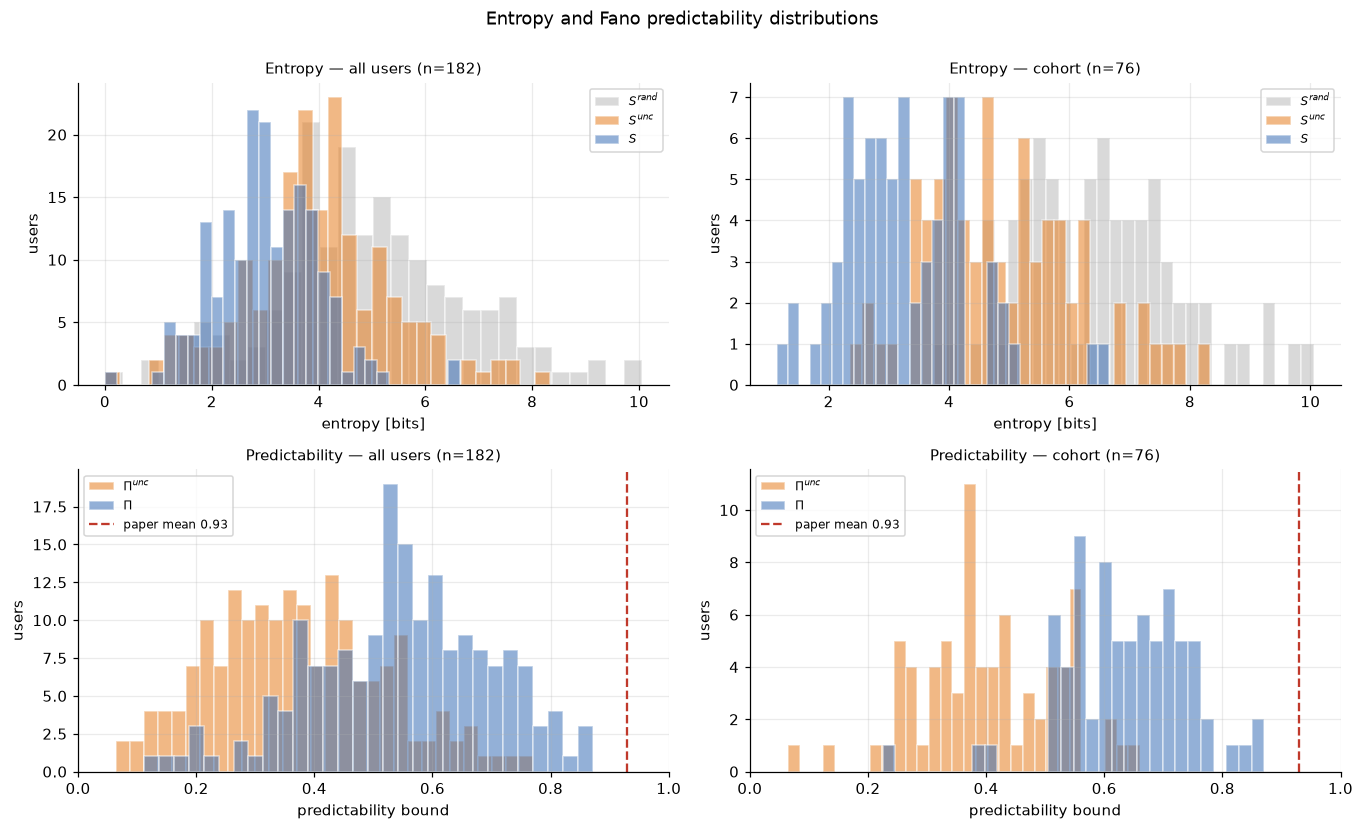

S <= S_unc <= S_rand holds for 93.4% of all users, 100.0% of cohort users


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.5))

def hist_overlay(ax, df, cols, labels, colors, title):
    for c, l, col in zip(cols, labels, colors):
        ax.hist(df[c], bins=30, alpha=0.55, label=l, color=col, edgecolor="white")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("entropy [bits]")
    ax.set_ylabel("users")
    ax.legend(fontsize=8)

hist_overlay(axes[0, 0], all_u, ["S_rand", "S_unc", "S_actual"],
             ["$S^{rand}$", "$S^{unc}$", "$S$"], ["#bbbbbb", "#e67e22", "#3b6fb6"],
             f"Entropy — all users (n={len(all_u)})")
hist_overlay(axes[0, 1], coh, ["S_rand", "S_unc", "S_actual"],
             ["$S^{rand}$", "$S^{unc}$", "$S$"], ["#bbbbbb", "#e67e22", "#3b6fb6"],
             f"Entropy — cohort (n={len(coh)})")

for ax, df, title in [(axes[1, 0], all_u, f"Predictability — all users (n={len(all_u)})"),
                      (axes[1, 1], coh, f"Predictability — cohort (n={len(coh)})")]:
    ax.hist(df["Pi_unc"], bins=30, alpha=0.55, label=r"$\Pi^{unc}$", color="#e67e22",
            edgecolor="white")
    ax.hist(df["Pi_actual"], bins=30, alpha=0.55, label=r"$\Pi$", color="#3b6fb6",
            edgecolor="white")
    ax.axvline(0.93, color="#c0392b", lw=1.5, ls="--", label="paper mean 0.93")
    ax.set_xlim(0, 1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("predictability bound")
    ax.set_ylabel("users")
    ax.legend(fontsize=8)

fig.suptitle("Entropy and Fano predictability distributions", y=1.0)
fig.tight_layout()
save(fig, "02_entropy_dists.png")
plt.show()

print(f"S <= S_unc <= S_rand holds for "
      f"{((all_u['S_actual'] <= all_u['S_unc']) & (all_u['S_unc'] <= all_u['S_rand'] + 1e-9)).mean():.1%}"
      " of all users, "
      f"{(coh['S_actual'] <= coh['S_unc']).mean():.1%} of cohort users")

## 3. $\Pi$ vs missingness, and actual vs uncorrelated entropy

Left: $\Pi$ against missingness $q$. Song et al. argue $\Pi$ is **robust to missingness**; here the raw correlation is in fact *positive* (sparser users have higher $\Pi$) — because a barely-logged user visits few distinct cells, which mechanically inflates $\Pi$. Within the better-covered cohort the correlation flips negative, matching the paper's intuition that more data reveals more structure.

Right: $S^{\mathrm{unc}}$ vs $S$ coloured by $N$ (distinct cells). The gap between the orange (uncorrelated) and blue (actual) diagonal is the value of *temporal order* — exactly the paper's core argument.

saved reports/02_pi_vs_q.png


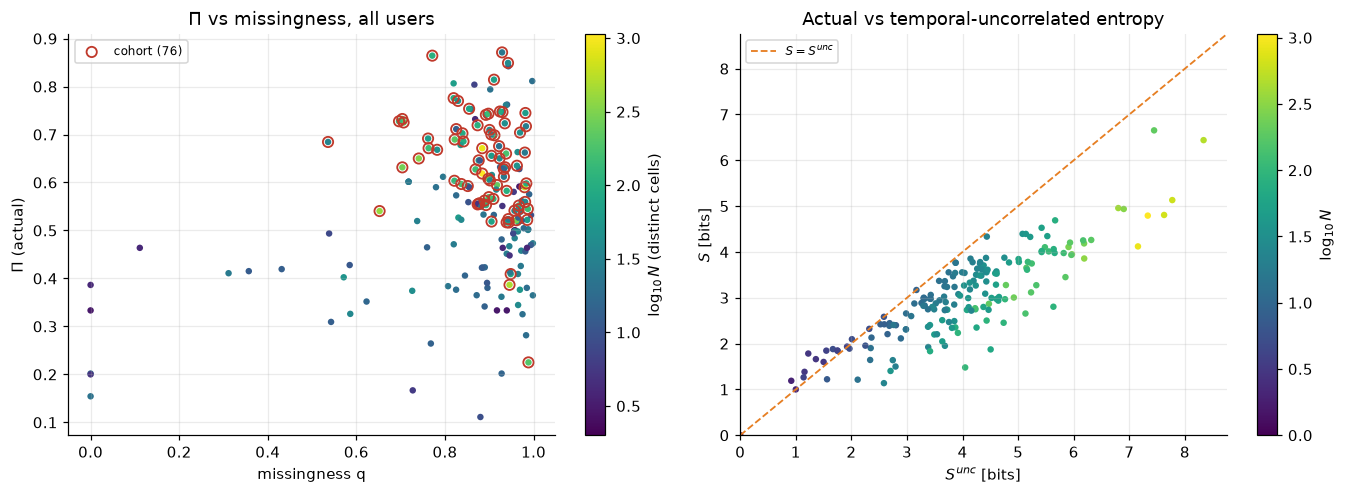

corr(Pi, q): all users +0.29, cohort -0.29
mean S/S_unc ratio: all 0.78, cohort 0.67


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

sc = axes[0].scatter(all_u["q"], all_u["Pi_actual"], c=np.log10(all_u["N"].clip(lower=1)),
                     s=18, cmap="viridis", linewidths=0)
axes[0].scatter(coh["q"], coh["Pi_actual"], facecolors="none", edgecolors="#c0392b",
                s=45, lw=1.2, label="cohort (76)")
fig.colorbar(sc, ax=axes[0], label=r"$\log_{10} N$ (distinct cells)")
axes[0].set_xlabel("missingness q")
axes[0].set_ylabel(r"$\Pi$ (actual)")
axes[0].set_title(r"$\Pi$ vs missingness, all users")
axes[0].legend(fontsize=8)

sc = axes[1].scatter(all_u["S_unc"], all_u["S_actual"], c=np.log10(all_u["N"].clip(lower=1)),
                     s=18, cmap="viridis", linewidths=0)
fig.colorbar(sc, ax=axes[1], label=r"$\log_{10} N$")
lim = [0, max(all_u["S_unc"].max(), all_u["S_actual"].max()) * 1.05]
axes[1].plot(lim, lim, color="#e67e22", lw=1.2, ls="--", label="$S = S^{unc}$")
axes[1].set_xlim(lim)
axes[1].set_ylim(lim)
axes[1].set_xlabel("$S^{unc}$ [bits]")
axes[1].set_ylabel("$S$ [bits]")
axes[1].set_title("Actual vs temporal-uncorrelated entropy")
axes[1].legend(fontsize=8)

fig.tight_layout()
save(fig, "02_pi_vs_q.png")
plt.show()

print(f"corr(Pi, q): all users {all_u['Pi_actual'].corr(all_u['q']):+.2f}, "
      f"cohort {coh['Pi_actual'].corr(coh['q']):+.2f}")
print(f"mean S/S_unc ratio: all {all_u.eval('S_actual / S_unc').mean():.2f}, "
      f"cohort {coh.eval('S_actual / S_unc').mean():.2f}")

## 4. Summary statistics

Mean / median / max of every measure, per subset. The q<=0.70 row is the task-defined analysis subset — 3 users only.

In [5]:
rows = []
for name, df in [("all 182", all_u), ("cohort 76", coh),
                 ("cohort & q<=0.95 (61)", coh_q95), ("cohort & q<=0.70 (3)", coh_q70)]:
    for c in ["S_rand", "S_unc", "S_actual", "Pi_rand", "Pi_unc", "Pi_actual"]:
        rows.append({"subset": name, "measure": c, "mean": df[c].mean(),
                     "median": df[c].median(), "max": df[c].max()})
summary = pd.DataFrame(rows).set_index(["subset", "measure"]).round(3)
summary

mean  median     max
subset                measure                         
all 182               S_rand     4.982   4.807  10.055
                      S_unc      4.016   4.009   8.336
                      S_actual   3.032   2.985   6.653
                      Pi_rand    0.061   0.036   0.500
                      Pi_unc     0.371   0.364   0.771
                      Pi_actual  0.548   0.553   0.871
cohort 76             S_rand     6.487   6.425  10.055
                      S_unc      4.871   4.649   8.336
                      S_actual   3.287   3.150   6.653
                      Pi_rand    0.016   0.012   0.077
                      Pi_unc     0.401   0.387   0.661
                      Pi_actual  0.637   0.641   0.871
cohort & q<=0.95 (61) S_rand     6.533   6.492  10.055
                      S_unc      4.815   4.656   8.336
                      S_actual   3.196   3.017   6.440
                      Pi_rand    0.016   0.011   0.077
                      Pi_unc     0.415   0.405   0.661
                      Pi_actual  0.652   0.656   0.871
cohort & q<=0.70 (3)  S_rand     6.934   7.087   8.626
                      S_unc      4.960   4.225   6.802
                      S_actual   3.407   2.773   4.958
                      Pi_rand    0.013   0.007   0.029
                      Pi_unc     0.430   0.432   0.543
                      Pi_actual  0.651   0.684   0.728

In [6]:
print(f"Pi_actual mean : all {all_u['Pi_actual'].mean():.3f} | cohort {coh['Pi_actual'].mean():.3f} "
      f"| cohort q<=0.95 {coh_q95['Pi_actual'].mean():.3f} | cohort q<=0.70 {coh_q70['Pi_actual'].mean():.3f}")
print(f"Pi_actual >0.7 : {all_u.eval('Pi_actual > 0.7').mean():.1%} of all users, "
      f"{coh.eval('Pi_actual > 0.7').mean():.1%} of cohort  (paper: 93% of users)")
print(f"Pi_unc mean    : all {all_u['Pi_unc'].mean():.3f} | cohort {coh['Pi_unc'].mean():.3f}")

Pi_actual mean : all 0.548 | cohort 0.637 | cohort q<=0.95 0.652 | cohort q<=0.70 0.651
Pi_actual >0.7 : 17.6% of all users, 30.3% of cohort  (paper: 93% of users)
Pi_unc mean    : all 0.371 | cohort 0.401


## 5. Honest discussion

**What reproduces.** The entropy ordering $S \le S^{unc} \le S^{rand}$ holds for 93.4% of users (100% within the cohort); actual entropy sits clearly below the uncorrelated bound (mean $S/S^{unc}$ = 0.78 for all users, 0.67 in the cohort), so temporal order matters, and on average Fano predictability from actual entropy (0.548) far exceeds the frequency-only bound $\Pi^{unc}$ (0.371). The qualitative claim of the paper — *human mobility is more predictable once time order is exploited* — survives.

**What does not.** The headline magnitude does not: mean $\Pi = 0.548$ over all 182 users (median 0.553) and **0.637 in the cohort** (0.652 for the well-covered q<=0.95 subset) vs the paper's **0.93**; only 17.6% of all users (30.3% of cohort) exceed $\Pi = 0.7$ vs 93% of users in the paper.

**Why, concretely.**
- *Data density.* GeoLife is opt-in GPS: median missingness **q = 0.905** (identical for all users and cohort), vs ~0.7 median in the phone data, and the phone users were additionally filtered to >= 0.5 calls/hour while logging. Our hourly grid has far more unknown slots than theirs.
- *Spatial resolution.* H3-res-8 (~0.74 km^2) is finer than a phone reception zone (~3 km^2), which raises $N$ and thus entropy relative to the paper.
- *Whole-window binning.* We bin each user's entire 2007-2012 span into hours; long device-off stretches count as unknown, deflating the known-slot density even for active users.
- *Small-N artefact.* $\Pi$ correlates *positively* with $q$ (+0.29) across all users: the sparsest users visit few cells, and low $N$ mechanically inflates $\Pi$. This is the mirror image of the paper's robustness claim and a reason to prefer the cohort numbers.
- *Estimator variance.* The LZ estimator is noisy on short sequences; users with a few hundred known hours get unstable $S$.

**Bottom line for the project.** Treat cohort $\Pi \approx 0.64$ (q<=0.95: 0.65) as the realistic accuracy ceiling for hourly next-cell prediction on this dataset — any predictor approaching it (see notebook 03: best reaches 0.23) still has a large gap to close, but "93% predictable" claims do not transfer to sparsely-logged GPS data.